<a href="https://colab.research.google.com/github/awanivinod/Preprocessing/blob/main/mshion_lerning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [4]:
data=sns.load_dataset('titanic')
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [6]:
data.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


handiling missing values:

In [7]:
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


persentage kittan null values

In [8]:
data.isnull().mean()*100

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
embarked,0.224467
class,0.000000
who,0.000000


In [9]:
data.drop("deck",axis=1,inplace=True)
data.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')

In [10]:
mean=data["age"].mean()
data["age"]=data["age"].fillna(mean)

In [11]:
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [12]:
data.dropna(inplace=True)

In [13]:
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


handiling duplicat values

In [14]:
data.duplicated().sum()

np.int64(111)

In [15]:
data.drop_duplicates(inplace=True)

In [16]:
data.shape

(778, 14)

out leyer undo nokkan

<Axes: ylabel='fare'>

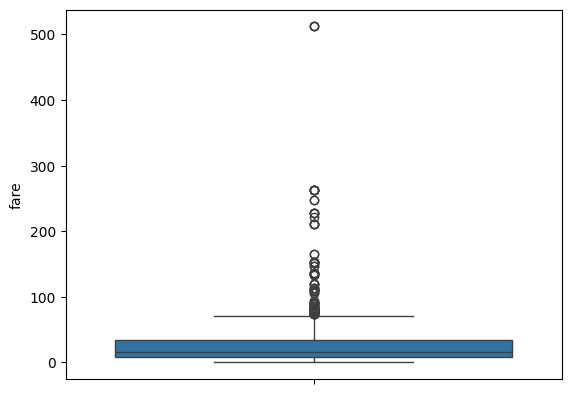

In [17]:
sns.boxplot(data["fare"])

In [18]:
q1,q2,q3=np.percentile(data["fare"],[25,50,75])
print(q1,q2,q3)

8.05 15.9 33.8906


In [19]:
iqr=q3-q1
print(iqr)

25.8406


In [20]:
lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr
outliers=[]
for i in data['fare']:
  if i<lower_limit or i>upper_limit:
    outliers.append(i)
print(outliers)

[263.0, 146.5208, 82.1708, 76.7292, 83.475, 73.5, 263.0, 77.2875, 247.5208, 73.5, 77.2875, 79.2, 146.5208, 113.275, 76.2917, 90.0, 83.475, 90.0, 79.2, 86.5, 512.3292, 79.65, 153.4625, 135.6333, 77.9583, 78.85, 91.0792, 151.55, 247.5208, 151.55, 110.8833, 108.9, 83.1583, 262.375, 164.8667, 134.5, 135.6333, 153.4625, 133.65, 134.5, 263.0, 75.25, 135.6333, 82.1708, 211.5, 227.525, 73.5, 120.0, 113.275, 90.0, 120.0, 263.0, 81.8583, 89.1042, 91.0792, 90.0, 78.2667, 151.55, 86.5, 108.9, 93.5, 221.7792, 106.425, 106.425, 110.8833, 227.525, 79.65, 110.8833, 79.65, 79.2, 78.2667, 153.4625, 77.9583, 76.7292, 73.5, 113.275, 133.65, 73.5, 512.3292, 76.7292, 211.3375, 110.8833, 227.525, 151.55, 227.525, 211.3375, 512.3292, 78.85, 262.375, 86.5, 120.0, 77.9583, 211.3375, 79.2, 120.0, 93.5, 83.1583, 89.1042, 164.8667, 83.1583]


In [21]:
data['fare']=np.where(data['fare']<lower_limit,lower_limit,data['fare'])
data['fare']=np.where(data['fare']>upper_limit,upper_limit,data['fare'])

<Axes: ylabel='fare'>

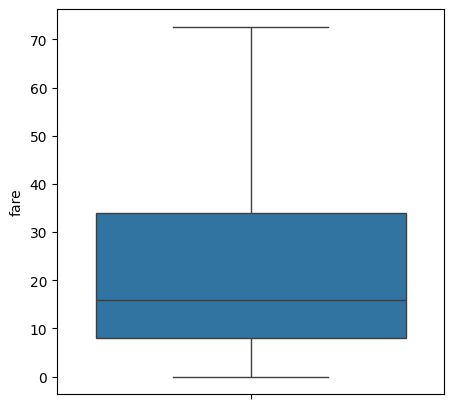

In [22]:
plt.figure(figsize=(5,5))
sns.boxplot(data['fare'])

handil skewnes

In [23]:
numeric_cols=data.select_dtypes(include=np.number)
numeric_cols.columns

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')

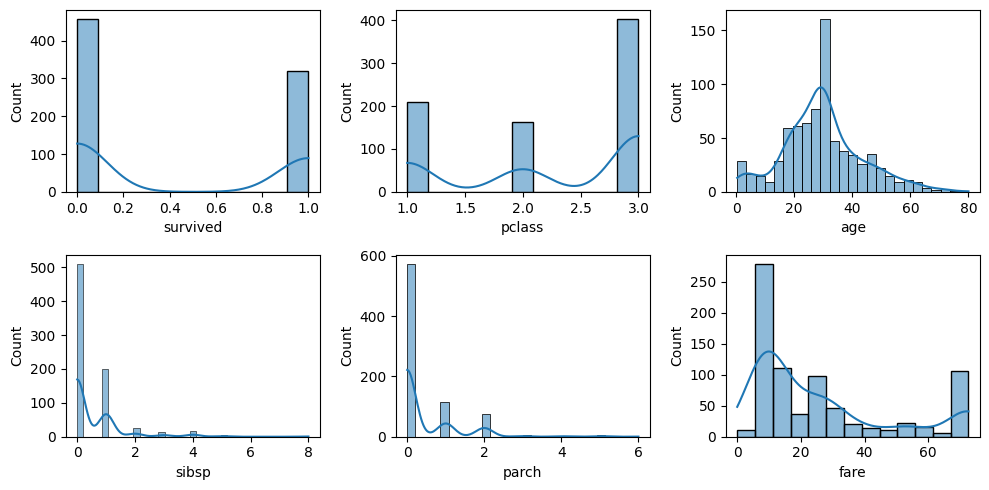

In [24]:
plt.figure(figsize=(10,5))
plotnumber=1
for i in numeric_cols:
  if plotnumber<=6:
    ax=plt.subplot(2,3,plotnumber)
    sns.histplot(numeric_cols[i],kde=True)
    plt.xlabel(i,fontsize=10)
    plotnumber+=1
plt.tight_layout()
plt.show()

In [25]:
numeric_cols.skew().sort_values(ascending=False)

,0
sibsp,3.042517
parch,2.619913
fare,1.092901
age,0.395728
survived,0.361169
pclass,-0.501068


skew remove cheyan

In [26]:
data["fare_log"]=np.log1p(data["fare"])

In [27]:
print("before transformation:",data['fare'].skew())
print("after transformation:",data["fare_log"].skew())

before transformation: 1.092901217175029
after transformation: -0.12263168576365706


<Axes: xlabel='fare_log', ylabel='Count'>

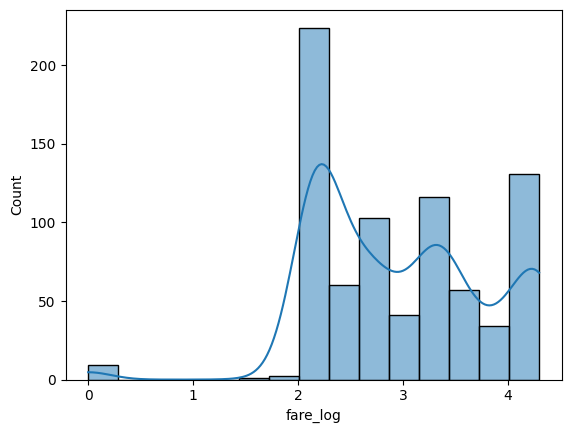

In [28]:
sns.histplot(data['fare_log'],kde=True)

In [31]:
data.drop(columns=['who','adult_male','embark_town','alive','alone'],axis=1,inplace=True)

In [32]:
data.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'fare_log'],
      dtype='object')

In [33]:
data["sex"].unique()


array(['male', 'female'], dtype=object)

In [34]:
pd.get_dummies(data["sex"])

,female,male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True
...,...,...
885,True,False
887,True,False
888,True,False
889,False,True


In [35]:
pd.get_dummies(data["sex"],dtype=int)

,female,male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1
...,...,...
885,1,0
887,1,0
888,1,0
889,0,1


In [36]:
data["sex"]=pd.get_dummies(data["sex"],dtype=int,drop_first=True)
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,fare_log
0,0,3,1,22.0,1,0,7.2500,S,Third,2.110213
1,1,1,0,38.0,1,0,71.2833,C,First,4.280593
2,1,3,0,26.0,0,0,7.9250,S,Third,2.188856
3,1,1,0,35.0,1,0,53.1000,S,First,3.990834
4,0,3,1,35.0,0,0,8.0500,S,Third,2.202765


In [37]:
data["embarked"].unique()

array(['S', 'C', 'Q'], dtype=object)

In [40]:
from sklearn.preprocessing import LabelEncoder

In [41]:
le=LabelEncoder()
data["embarked"]=le.fit_transform(data['embarked'])

In [42]:
data["embarked"].unique()

array([2, 0, 1])

In [43]:
data["class"].unique()

['Third', 'First', 'Second']
Categories (3, object): ['First', 'Second', 'Third']

In [45]:

data["class"]=data["class"].map({'first':1,'second':2,'third':3})
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,fare_log
0,0,3,1,22.0,1,0,7.2500,2,NaN,2.110213
1,1,1,0,38.0,1,0,71.2833,0,NaN,4.280593
2,1,3,0,26.0,0,0,7.9250,2,NaN,2.188856
3,1,1,0,35.0,1,0,53.1000,2,NaN,3.990834
4,0,3,1,35.0,0,0,8.0500,2,NaN,2.202765


In [46]:
data.drop('fare_log',axis=1,inplace=True)
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class
0,0,3,1,22.0,1,0,7.2500,2,NaN
1,1,1,0,38.0,1,0,71.2833,0,NaN
2,1,3,0,26.0,0,0,7.9250,2,NaN
3,1,1,0,35.0,1,0,53.1000,2,NaN
4,0,3,1,35.0,0,0,8.0500,2,NaN


correlation

In [47]:
correlation=data.corr()
correlation

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class
survived,1.000000,-0.333291,-0.511686,-0.084185,-0.036044,0.071352,0.301793,-0.157858,NaN
pclass,-0.333291,1.000000,0.113210,-0.335180,0.085055,0.037218,-0.736430,0.181243,NaN
sex,-0.511686,0.113210,1.000000,0.099034,-0.099980,-0.239210,-0.213620,0.101821,NaN
age,-0.084185,-0.335180,0.099034,1.000000,-0.279150,-0.185872,0.135846,-0.034728,NaN
sibsp,-0.036044,0.085055,-0.099980,-0.279150,1.000000,0.380174,0.268348,0.064530,NaN
parch,0.071352,0.037218,-0.239210,-0.185872,0.380174,1.000000,0.243479,0.044173,NaN
fare,0.301793,-0.736430,-0.213620,0.135846,0.268348,0.243479,1.000000,-0.231762,NaN
embarked,-0.157858,0.181243,0.101821,-0.034728,0.064530,0.044173,-0.231762,1.000000,NaN
class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cmap Code  | Colour Combination         |
| ---------- | -------------------------- |
| ` viridis` | Purple → Green → Yellow    |
| `plasma`   | Purple → Pink → Yellow     |
| `inferno`  | Black → Red → Yellow       |
| `magma`    | Black → Purple → White     |
| `cividis`  | Blue → Yellow              |
| `YlGnBu`   | Yellow → Green → Blue      |
| `YlGn`     | Yellow → Green             |
| `YlOrRd`   | Yellow → Orange → Red      |
| `YlOrBr`   | Yellow → Orange → Brown    |
| `Blues`    | Light Blue → Dark Blue     |
| `Greens`   | Light Green → Dark Green   |
| `Reds`     | Light Red → Dark Red       |
| `Purples`  | Light Purple → Dark Purple |
| `Oranges`  | Light Orange → Dark Orange |
| `Greys`    | Light Grey → Dark Grey     |
| `BuGn`     | Blue → Green               |
| `BuPu`     | Blue → Purple              |
| `GnBu`     | Green → Blue               |
| `PuBu`     | Purple → Blue              |
| `PuBuGn`   | Purple → Blue → Green      |
| `PuRd`     | Purple → Red               |
| `RdPu`     | Red → Purple       

<Axes: >

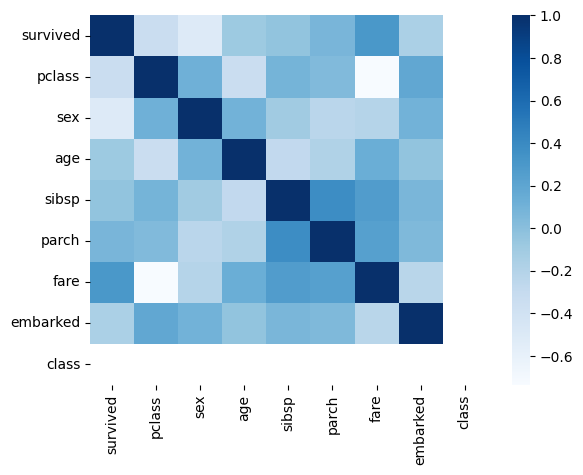

In [49]:
sns.heatmap(correlation,cmap="Blues")

<Axes: >

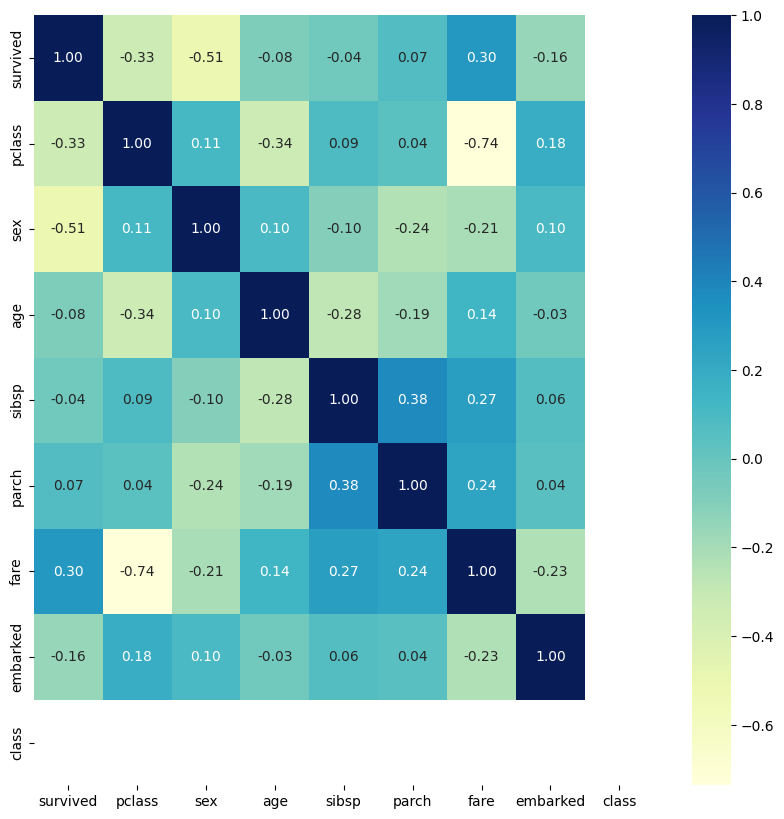

In [50]:
plt.figure(figsize=(10,10))
sns.heatmap(correlation,annot=True,cmap="YlGnBu",fmt=".2f")

<Axes: >

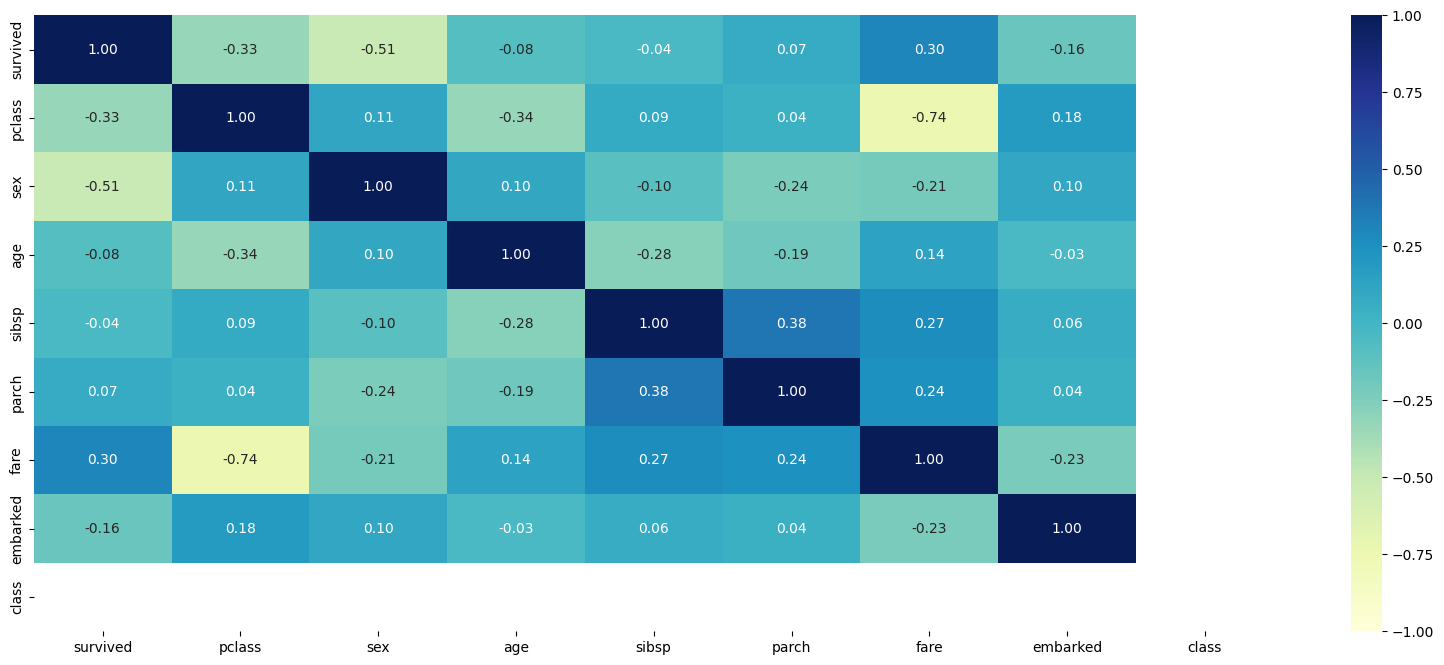

In [53]:
plt.figure(figsize=(20,8))
sns.heatmap(correlation,annot=True,vmin=-1,vmax=1,fmt=".2f",cmap="YlGnBu")

<Axes: >

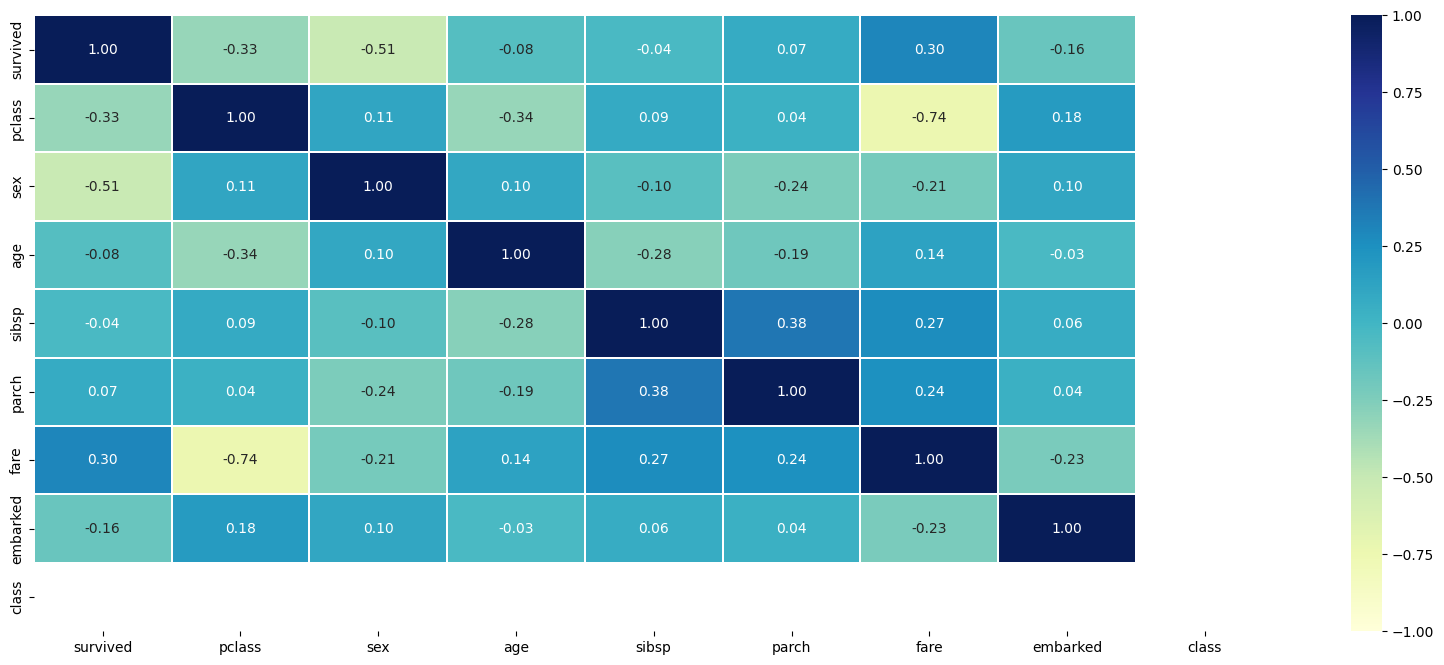

In [54]:
plt.figure(figsize=(20,8))
sns.heatmap(correlation,annot=True,vmin=-1,vmax=1,fmt=".2f",linewidths=.2,cmap="YlGnBu")

<Axes: xlabel='survived', ylabel='count'>

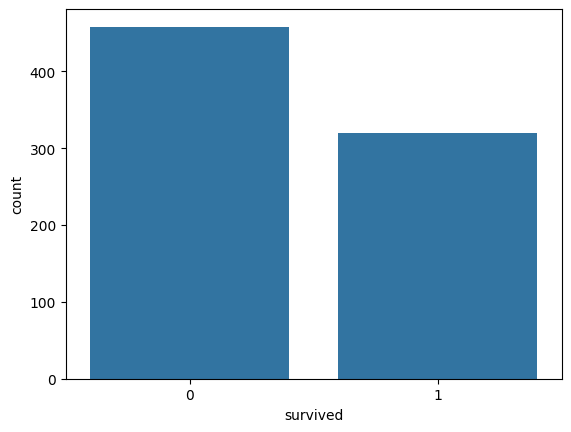

In [55]:
sns.countplot(data=data,x="survived")

In [56]:
!git clone https://github.com/awanivinod/preprocesing.git

Cloning into 'preprocesing'...
